In [ ]:
!wget -q -c -O rev1-benchmark-data.tar.gz https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-benchmark-data.tar.gz
!git clone --quiet --depth 1 --branch rev1 https://github.com/huboqiang/omnialigner.git omnialigner-rev1

from pathlib import Path
import hashlib, tarfile, sys
assert (3, 10) <= sys.version_info[:2] < (3, 12), "Use a Python 3.10 or 3.11 Jupyter kernel."
archive = Path("rev1-benchmark-data.tar.gz").resolve()
checkout = Path("omnialigner-rev1").resolve()
assert archive.is_file() and (checkout / ".git").is_dir(), "Download or clone failed; inspect the messages above."
assert hashlib.sha256(archive.read_bytes()).hexdigest() == "9b98464f0b6625bae48514c601b740caee50aeb008525f103a362fc7a630d7d3", "Data archive checksum mismatch"
destination = checkout / "benchmarks/rev1"
with tarfile.open(archive, "r:gz") as bundle:
    for member in bundle.getmembers():
        if member.name == "NCS" or member.name.startswith("NCS/"):
            member.name = "OmniAligner" + member.name[3:]
        target = (destination / member.name).resolve()
        assert target.is_relative_to(destination) and not (member.issym() or member.islnk()), "Unsafe archive member"
    bundle.extractall(destination)
PACKAGE_ROOT = destination / "OmniAligner"
print("Downloaded and verified rev1 data; package:", PACKAGE_ROOT.name)

!wget -q -c -O rev1-dlpfc-workflow.tar.gz https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-dlpfc-workflow.tar.gz
workflow_archive = Path("rev1-dlpfc-workflow.tar.gz").resolve()
assert hashlib.sha256(workflow_archive.read_bytes()).hexdigest() == "68a982fec593f7a8c20d162bf5114e24b0ed3ba1e1205a6683ca6018a09c57fb"
with tarfile.open(workflow_archive, "r:gz") as bundle:
    for member in bundle.getmembers():
        assert (destination / member.name).resolve().is_relative_to(destination)
        assert not (member.issym() or member.islnk())
    bundle.extractall(destination)


In [ ]:
%pip install -q -r {PACKAGE_ROOT / "requirements.txt"}
%pip install -q torch==2.2.0 --index-url https://download.pytorch.org/whl/cpu
%cd {PACKAGE_ROOT}


# OmniAligner: DLPFC alignment and agent-guided refinement walkthrough

**Four consecutive sections: 151673–151676; 14,243 spots.** Follow the actual recorded workflow:

**Original coordinates and annotations → feature matching → pairwise alignment → stack/affine review → agent-directed local refinement → numerical optimization → selected checkpoint → coordinates → six benchmark scores.**

This is an executable walkthrough of the recorded development run. It **recomputes the raw-to-coarse transform, checkpoint inference, coarse/final scores and numerical summaries**. Detector outputs, agent judgments and the two 1,000-update optimization trajectories are replayed from the original hash-bound records; running this notebook does **not** call an LLM or retrain the optimizer. No API key or private directory is needed. The distinction is shown at each step.

The agent reviewed geometric evidence and carried local residuals forward to nonlinear optimization; it did not directly edit cell coordinates. The source run's final geometric-admission check remained false despite successful scoring. This status is retained below, rather than treating a molecular score as proof of anatomical correctness.

In [2]:
from pathlib import Path
import os, sys, json, csv, hashlib, importlib.metadata, warnings, time
import numpy as np
import pandas as pd
import anndata as ad
import scipy.sparse as sp
from IPython.display import display

def locate_repository():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "notebooks/OmniAligner_NCS_manifest.json").is_file():
            return candidate
    raise FileNotFoundError("Run from this repository or its notebooks directory")
REPO_ROOT = locate_repository()
DATA_ROOT = REPO_ROOT / "data"
INPUT_ROOT = DATA_ROOT
input_records = json.loads((INPUT_ROOT / "evaluation_inputs_manifest.json").read_text())
input_index = {(x["dataset"], x["layer"]): x for x in input_records}
OUTPUT_ROOT = REPO_ROOT / "results" / "workflow_DLPFC"
DATASETS = ["DLPFC"]
VERIFY_SOURCE_HASHES = True
ATOL = 1e-10
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
METRICS = ["PCC", "CosSim", "SSIM", "MI", "MSE", "Region"]
NATIVE_KEYS = ["PCC", "CosSim", "SSIM", "MI", "Expression_MSE_native_ASSD_bygrid", "Accuracy"]
manifest = json.loads((REPO_ROOT / "notebooks/OmniAligner_NCS_manifest.json").read_text())
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()
def save_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    temporary.replace(path)
reference_path = REPO_ROOT / "notebooks/OmniAligner_NCS_reference.csv"
assert sha256(reference_path) == manifest["expected_table_sha256"]
reference = pd.read_csv(reference_path).set_index("Dataset")
print("Reference values (not recomputed yet)")
display(reference[METRICS].round(6))

Reference values (not recomputed yet)


,PCC,CosSim,SSIM,MI,MSE,Region
Dataset,,,,,,
DLPFC,0.547930,0.783503,0.531970,0.299724,0.127579,0.884759
MHPR,0.540881,0.869558,0.527731,0.252730,1.218373,0.759039
MMPC,0.197483,0.666920,0.193019,0.069390,81.048677,0.871546
MPC,0.333290,0.625865,0.323609,0.152123,0.341752,0.978106
E14_16,0.411842,0.947845,0.414820,0.191671,0.125625,0.643624
MLN,0.812007,0.982588,0.811243,0.809955,0.055572,0.406042


In [3]:
sys.path.insert(0, str(REPO_ROOT / "src"))

inventory = []
for dataset in DATASETS:
    config = manifest["datasets"][dataset]
    assert sha256(DATA_ROOT / config["coordinates"]) == config["coordinates_sha256"], dataset
    for item in config["weights"]:
        assert sha256(DATA_ROOT / item["path"]) == item["sha256"], item["path"]
    for layer in range(len(config["sections"])):
        record = input_index[(dataset, layer)]
        source = INPUT_ROOT / record["path"]
        assert source.is_file(), source
        assert record["source_h5ad_sha256"] == config["source_sha256"][layer]
        if VERIFY_SOURCE_HASHES:
            assert sha256(source) == record["sha256"], source
    inventory.append({"Dataset": dataset, "Sections": len(config["sections"]), "Pairs": config["pairs"],
                      "Original cells": config["original_cells"], "Scored cells": config["evaluation_cells"],
                      "Gene arguments": len(config["evaluation_genes"]), "Unique genes": len(set(config["evaluation_genes"]))})
display(pd.DataFrame(inventory).set_index("Dataset"))
save_json(OUTPUT_ROOT / "INPUT_VALIDATION.json", {"source_hashes_checked": VERIFY_SOURCE_HASHES, "datasets": DATASETS, "inventory": inventory})

,Sections,Pairs,Original cells,Scored cells,Gene arguments,Unique genes
Dataset,,,,,,
DLPFC,4,3,14243,14243,123,117


## Metric calculations, shown explicitly

For every adjacent section pair, `coords` contains the two XY arrays and a shared **10 × 10 overlap grid**. For each gene, `X` contains its two expression vectors. We call the functions below directly: `for metric in [PCC, CosSim, SSIM, MI, MSE]: metric(X, coords)`. `Region(labels, coords)` measures nearest-neighbor regional-label agreement.

| Metric | Calculation |
|---|---|
| PCC ↑ | Pearson correlation between the two vectors of grid-mean expression |
| CosSim ↑ | Dot product divided by the product of vector norms |
| SSIM ↑ | Native luminance × contrast × structure, after separately scaling each vector by its maximum |
| MI ↑ | Native `mutual_info_regression`, with seed 0 reset for each gene |
| MSE ↓ | Mean squared difference between the unscaled grid-mean vectors |
| Region ↑ | Fraction of moving-section labels matching the nearest reference label inside the overlap box |

The grid uses the original half-open bin boundaries and native density threshold. Region uses the original closed overlap bounds. Gene arguments (including repeated names) and adjacent pairs receive equal weights. Missing/nonfinite values are not silently dropped. Native insufficient-grid fallback values remain explicit and are excluded from eligible comparison ranks.

In [4]:
import math
from scipy.stats import pearsonr
from scipy.spatial import cKDTree
from sklearn.feature_selection import mutual_info_regression

### Shared spatial support

In [5]:
def shared_grid(reference_xy, moving_xy):
    """Use the original overlap box, half-open bins and native density threshold."""
    xy = (reference_xy, moving_xy)
    x_min = max(np.min(reference_xy[:, 0]), np.min(moving_xy[:, 0]))
    x_max = min(np.max(reference_xy[:, 0]), np.max(moving_xy[:, 0]))
    y_min = max(np.min(reference_xy[:, 1]), np.min(moving_xy[:, 1]))
    y_max = min(np.max(reference_xy[:, 1]), np.max(moving_xy[:, 1]))
    bins = []
    for i in range(10):
        for j in range(10):
            x_start = x_min + i * (x_max - x_min) / 10
            y_start = y_min + j * (y_max - y_min) / 10
            x_end = x_start + (x_max - x_min) / 10
            y_end = y_start + (y_max - y_min) / 10
            bins.append((x_start, x_end, y_start, y_end))

    def inside(points, box):
        x_start, x_end, y_start, y_end = box
        return ((points[:, 0] >= x_start) & (points[:, 0] < x_end)
                & (points[:, 1] >= y_start) & (points[:, 1] < y_end))

    counts = [[np.sum(inside(points, box)) for box in bins] for points in xy]
    threshold = min(np.mean(counts[0]), np.mean(counts[1])) / 2
    labels = [np.full(len(points), None, dtype=object) for points in xy]
    counter = 1
    for index, box in enumerate(bins):
        keep = counts[0][index] >= threshold and counts[1][index] >= threshold
        name = f"Grid_{counter}" if keep else "NonOverlap"
        for points, values in zip(xy, labels):
            values[inside(points, box)] = name
        if keep:
            counter += 1
    return {"xy": xy, "grid_labels": labels}

### Expression means in the retained bins

In [6]:
def grid_expression(X, coords):
    """Mean expression per retained bin, sorted by the native string grid label."""
    means = []
    for expression, labels in zip(X, coords["grid_labels"]):
        frame = pd.DataFrame({"expression": expression, "grid_label": labels})
        frame = frame[(frame.grid_label != "NonOverlap") & frame.grid_label.notnull()]
        means.append(frame.groupby("grid_label").mean().sort_index()["expression"].to_numpy())
    return means

### 1. Pearson correlation

In [7]:
def PCC(X, coords):
    a, b = grid_expression(X, coords)
    return 0.0 if a.size < 2 or b.size < 2 else pearsonr(a, b).statistic

### 2. Cosine similarity

In [8]:
def CosSim(X, coords):
    a, b = grid_expression(X, coords)
    return 0.0 if a.size < 2 or b.size < 2 else a.dot(b) / (np.linalg.norm(a) * np.linalg.norm(b))

### 3. Structural similarity

In [9]:
def SSIM(X, coords):
    a, b = grid_expression(X, coords)
    if a.size < 2 or b.size < 2:
        return 0.0
    # Native convention: separately divide each gene's grid vector by its maximum.
    a, b = a / a.max(), b / b.max()
    mu_a, mu_b = a.mean(), b.mean()
    sigma_a = np.sqrt(((a - mu_a) ** 2).mean())
    sigma_b = np.sqrt(((b - mu_b) ** 2).mean())
    covariance = ((a - mu_a) * (b - mu_b)).mean()
    C1, C2 = 0.01 ** 2, 0.03 ** 2
    C3 = C2 / 2
    luminance = (2 * mu_a * mu_b + C1) / (mu_a ** 2 + mu_b ** 2 + C1)
    contrast = (2 * sigma_a * sigma_b + C2) / (sigma_a ** 2 + sigma_b ** 2 + C2)
    structure = (covariance + C3) / (sigma_a * sigma_b + C3)
    return luminance * contrast * structure

### 4. Mutual information

In [10]:
def MI(X, coords):
    a, b = grid_expression(X, coords)
    if a.size < 2 or b.size < 2:
        return 0.0
    # Reset the seed as in the frozen scorer, including its jitter convention.
    np.random.seed(0)
    return mutual_info_regression(a.reshape(-1, 1), b)[0]

### 5. Expression mean squared error

In [11]:
def MSE(X, coords):
    a, b = grid_expression(X, coords)
    if a.size < 2 or b.size < 2:
        return 100.0  # Native fallback, excluded from eligible table rankings.
    return np.mean(np.square(a - b))

### 6. Regional-label agreement

In [12]:
def Region(labels, coords):
    """Moving-to-reference nearest-neighbor label agreement in the overlap box."""
    reference_xy, moving_xy = coords["xy"]
    x_min = max(np.min(reference_xy[:, 0]), np.min(moving_xy[:, 0]))
    x_max = min(np.max(reference_xy[:, 0]), np.max(moving_xy[:, 0]))
    y_min = max(np.min(reference_xy[:, 1]), np.min(moving_xy[:, 1]))
    y_max = min(np.max(reference_xy[:, 1]), np.max(moving_xy[:, 1]))
    keep = [((points[:, 0] >= x_min) & (points[:, 0] <= x_max)
             & (points[:, 1] >= y_min) & (points[:, 1] <= y_max))
            for points in (reference_xy, moving_xy)]
    reference_xy, moving_xy = reference_xy[keep[0]], moving_xy[keep[1]]
    reference_labels = np.asarray(labels[0])[keep[0]]
    moving_labels = np.asarray(labels[1])[keep[1]]
    _, neighbors = cKDTree(reference_xy).query(moving_xy)
    if len(neighbors) == 0:
        return 0.0
    matches = sum(reference_labels[target] == moving_labels[index]
                  for index, target in enumerate(neighbors)
                  if target < len(reference_labels) and index < len(moving_labels))
    return matches / len(neighbors)

In [13]:
from io import BytesIO
from IPython.display import Image, Markdown
import matplotlib.pyplot as plt

WORKFLOW = DATA_ROOT / "workflow/DLPFC"
evidence_manifest = json.loads((WORKFLOW / "MANIFEST.json").read_text())
for item in evidence_manifest["files"]:
    assert sha256(WORKFLOW / item["path"]) == item["sha256"], item["path"]
print("Verified original workflow records:", len(evidence_manifest["files"]))

def show_figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

def read_record(relative):
    return json.loads((WORKFLOW / relative).read_text())

Verified original workflow records: 173


## 1. Original spatial input

**Recomputed display.** Load original spot coordinates and supplied regional annotations. These plots show the annotation-assisted inputs; they are not independent anatomical ground truth. Colors below are for display. The recorded matcher overlays in the next step preserve the original rendering used in the experiment.

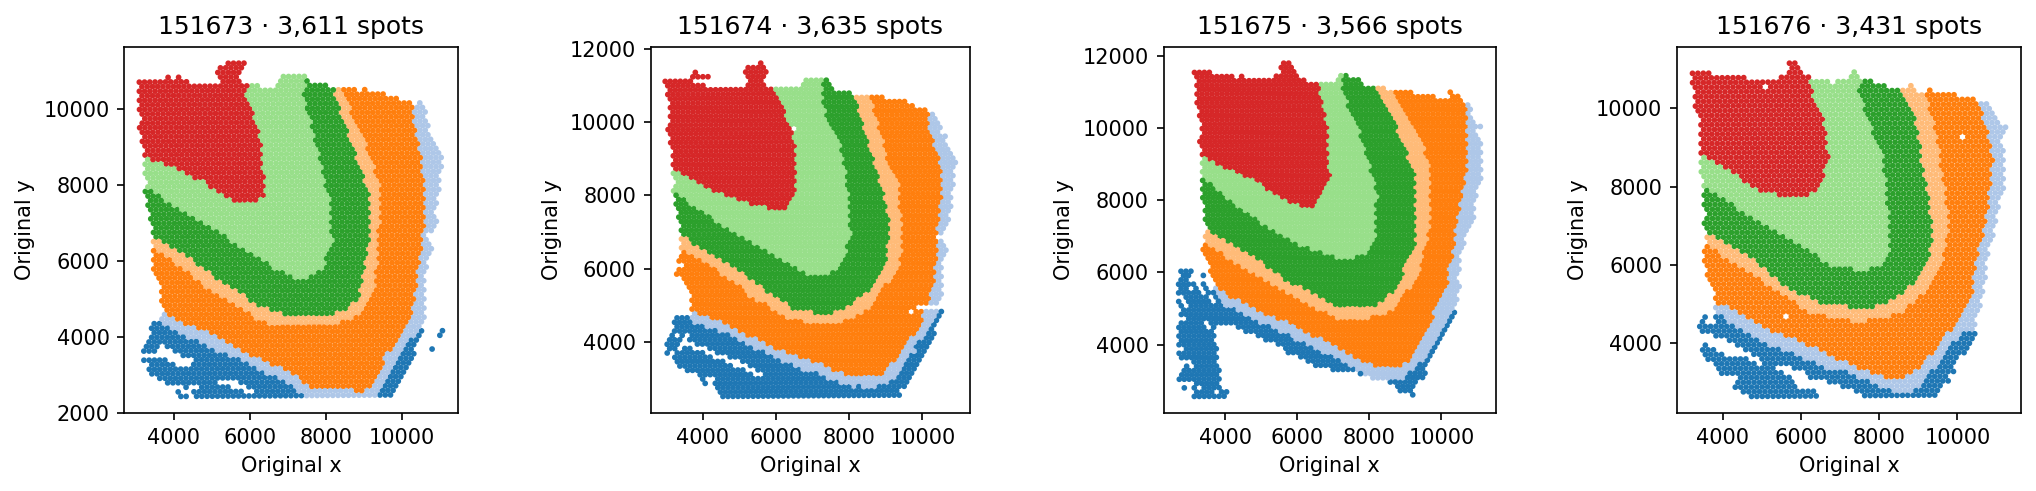

In [14]:
raw_sections=[]
for layer in range(4):
    with np.load(INPUT_ROOT / input_index[("DLPFC",layer)]["path"],allow_pickle=False) as z:
        raw_sections.append({"xy":z["raw_xy"].copy(),"labels":z["labels"].astype(str),"ids":z["ids"].astype(str)})
labels=sorted(set(np.concatenate([x["labels"] for x in raw_sections])))
palette={label:plt.get_cmap("tab20")(i % 20) for i,label in enumerate(labels)}
fig,axes=plt.subplots(1,4,figsize=(14,3.4))
for layer,(ax,section) in enumerate(zip(axes,raw_sections)):
    ax.scatter(*section["xy"].T,c=[palette[x] for x in section["labels"]],s=3)
    ax.set_title(f"{manifest['datasets']['DLPFC']['sections'][layer]} · {len(section['xy']):,} spots")
    ax.set_aspect("equal");ax.set_xlabel("Original x");ax.set_ylabel("Original y")
fig.tight_layout();show_figure(fig)

## 2. Feature matches, pairwise alignment and stack geometry

**Archived detector/stage outputs; recomputed summaries.** The saved image correspondences and stage overlays show the middle adjacent pair (151674→151675). All three pairs remain in the data package. The table recomputes residual distances directly from the saved match endpoints. Stage-specific match sets can differ, so these are diagnostics rather than a controlled estimate of stage contribution.

The archived stack configuration has `refine_pose=False`; its subsequent affine stage retained the stack geometry. The agent's local-refinement decisions are shown in step 3. This avoids implying that the agent numerically optimized a stack transform itself.

,Stage,Pair,Matches,Median residual (frame px),95th percentile (frame px),Local review required,Diagnostic status
0,pairwise,1,7688,12.369,32.823,True,WITHIN_COARSE_LIMITS
1,pairwise,2,7638,12.722,29.744,True,WITHIN_COARSE_LIMITS
2,pairwise,3,7804,7.684,16.679,True,WITHIN_COARSE_LIMITS
3,stack,1,7688,12.369,32.823,True,WITHIN_COARSE_LIMITS
4,stack,2,7638,12.933,30.478,True,WITHIN_COARSE_LIMITS
5,stack,3,7804,7.534,16.858,True,WITHIN_COARSE_LIMITS
6,affine,1,7688,12.369,32.823,True,WITHIN_COARSE_LIMITS
7,affine,2,7638,12.933,30.478,True,WITHIN_COARSE_LIMITS
8,affine,3,7804,7.534,16.858,True,WITHIN_COARSE_LIMITS
9,nonrigid,1,7688,9.494,31.287,True,WITHIN_COARSE_LIMITS


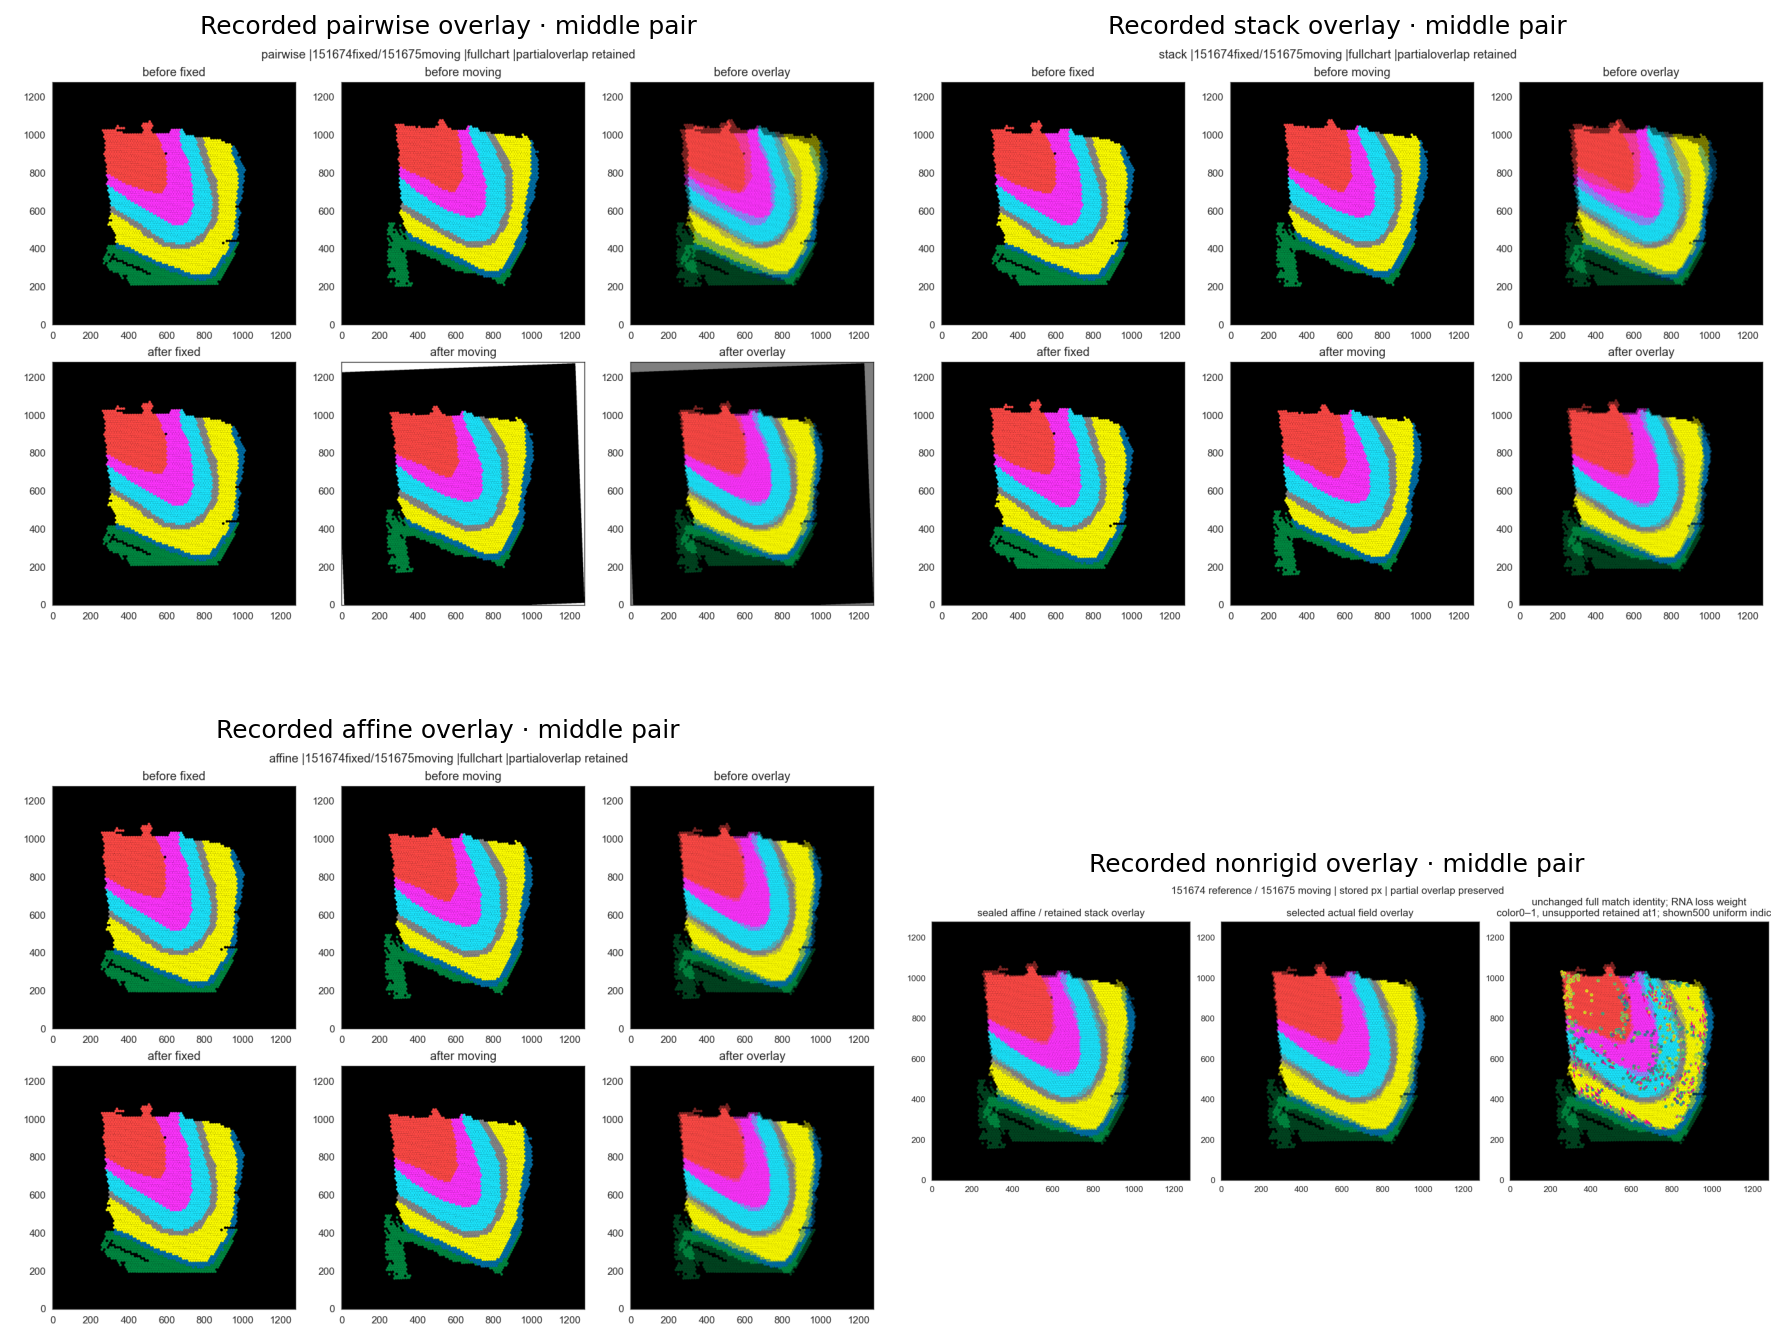

In [15]:
stage_names=["pairwise","stack","affine","nonrigid"]
diagnostic_rows=[]
for stage in stage_names:
    for pair in range(3):
        with np.load(WORKFLOW / f"{stage}/pair_{pair}/matches.npz",allow_pickle=False) as m:
            residual=np.linalg.norm(m["moving"]-m["reference"],axis=1)
            count=len(residual)
        record=read_record(f"{stage}/pair_{pair}/diagnostics.json")
        diagnostic_rows.append({"Stage":stage,"Pair":pair+1,"Matches":count,
          "Median residual (frame px)":float(np.median(residual)),
          "95th percentile (frame px)":float(np.quantile(residual,.95)),
          "Local review required":record.get("local_review_required"),
          "Diagnostic status":record.get("status")})
diagnostics=pd.DataFrame(diagnostic_rows)
display(diagnostics.round(3))
diagnostics.to_csv(OUTPUT_ROOT / "stage_diagnostics.csv",index=False)

fig,axes=plt.subplots(2,2,figsize=(12,10))
for ax,stage in zip(axes.flat,stage_names):
    ax.imshow(plt.imread(WORKFLOW / f"{stage}/pair_1/overlay.png"))
    ax.set_title(f"Recorded {stage} overlay · middle pair");ax.axis("off")
fig.tight_layout();show_figure(fig)

## 3. What the agent actually reviewed and decided

**Archived agent output.** Each stage was reviewed using its overlays, spatially distributed matches and local residual diagnostics. A coarse-stage `PASS` permitted continuation with explicit local obligations; it was not final acceptance of anatomical alignment. The supervisor's recorded action was `DEFER_LOCAL_TO_NR`: keep the usable global pose and inspect the unresolved local groups after nonlinear refinement.

The example below includes the middle pair's actual review and the residual image it referred to. The agent's text is evidence of its decision process, not an independent biological measurement.

,Stage,Pair,Recorded verdict,Concerns
0,affine,151673 → 151674,PASS,0
1,affine,151674 → 151675,PASS,0
2,affine,151675 → 151676,PASS,0
3,pairwise,151673 → 151674,PASS,0
4,pairwise,151674 → 151675,PASS,0
5,pairwise,151675 → 151676,PASS,0
6,stack,151673 → 151674,PASS,0
7,stack,151674 → 151675,PASS,0
8,stack,151675 → 151676,PASS,0


> Stack overlay (before/after fixed, moving, blend) shows the same laminar architecture (red, magenta, cyan, yellow, green bands) in both charts with no visible rotation, mirroring, or coherent single-axis scale change; area_ratio [reference, moving] = 1.0261/1.0025 and moving/reference spacing ratio 0.9895 are near unity.

> A coherent lower-group displacement remains: cells [0,0] and [1,0] have norm 2.01 and 2.48 spacings (102 and 235 matches) and flagged component cells [0,1,2]; a second, milder component over bins [1,1],[2,1],[3,1],[1,2],[2,2] peaks at 1.155 spacings. This is the group already covered by the bound root DEFER_LOCAL_TO_NR ruling (obligation about 2.01 and 2.48 input spacings, RNA weight median 0.589 with 170/592 negative-cosine conflicts), which accepts a trusted local-correction obligation at this coarse stage; it is a carry-forward obligation, not a stack-stage blocker, and requires a fresh EXPLAINED_ACCEPTED ruling at NONRIGID.

**Recorded next action:** `DEFER_LOCAL_TO_NR`

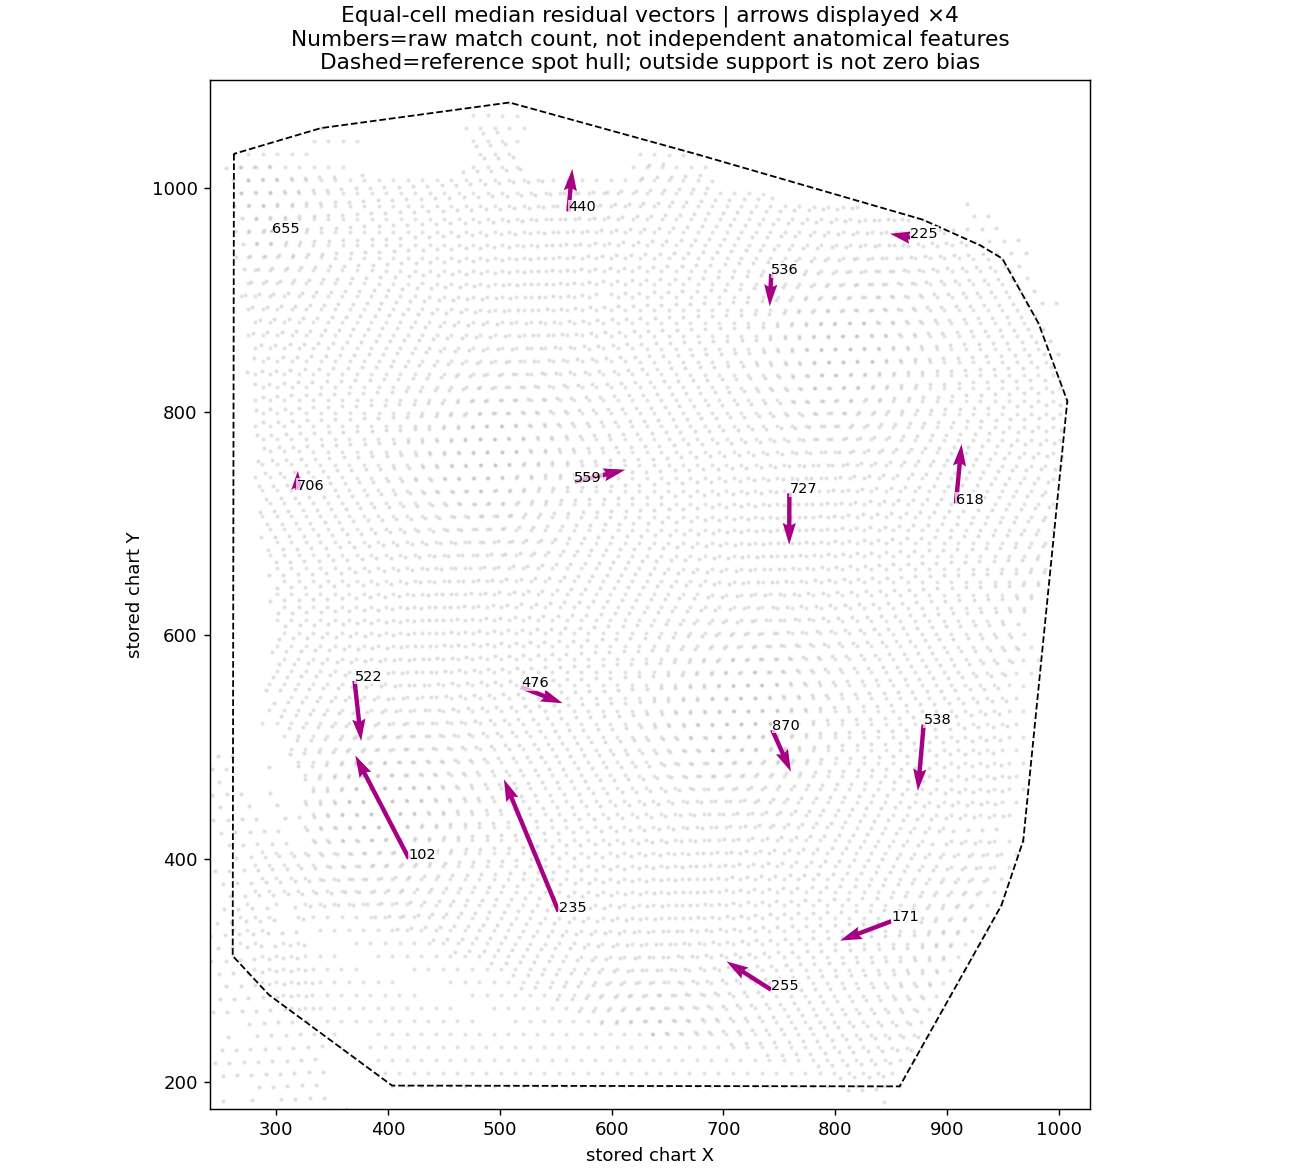

In [16]:
review_rows=[]
reviews={}
for path in sorted((WORKFLOW / "reviews").glob("*.json")):
    if path.stem.endswith("_admission"):continue
    review=json.loads(path.read_text());reviews[path.stem]=review
    review_rows.append({"Stage":path.stem.split("_")[0],"Pair":path.stem.split("_")[1]+" → "+path.stem.split("_")[2],"Recorded verdict":review["verdict"],"Concerns":len(review.get("concerns",[]))})
display(pd.DataFrame(review_rows))
middle=next(v for k,v in reviews.items() if k.startswith("stack_151674_151675_"))
observations=middle.get("observations",[])
selected_observations=[observations[0]]+[s for s in observations if "coherent lower-group" in s]
for observation in selected_observations:
    display(Markdown("> "+observation))
root_decisions=read_record("ROOT_COARSE_RESOLUTIONS.json")
decision=root_decisions["decisions"][middle["manifest_sha256"]]
display(Markdown("**Recorded next action:** `"+decision["action"]+"`"))
display(Image(filename=str(WORKFLOW / "stack/pair_1/balanced_residuals.png"),width=900))

## 4. Numerical optimizer refinement and checkpoint selection

**Archived optimization trace; recomputed checkpoint selection.** Two predeclared RNA-loss weights were calibrated using training gradients. Each candidate received 1,000 updates. The numerical optimizer updated the deformation parameters; the agent did not write coordinates. Selection used a fixed 64-gene development-validation panel, separate from the final benchmark panel. The curve below therefore is **not** the final benchmark PCC.

We retain both candidates and every recorded update, and select the checkpoint again from the archived validation curve using the recorded tie rule. This step is trace replay, not a fresh training run.

,name,weight_rna,seed,max_updates
0,A,8.834500,0,1000
1,B,17.669001,0,1000


Recomputed selection: A step 100 validation PCC 0.6625412759215882


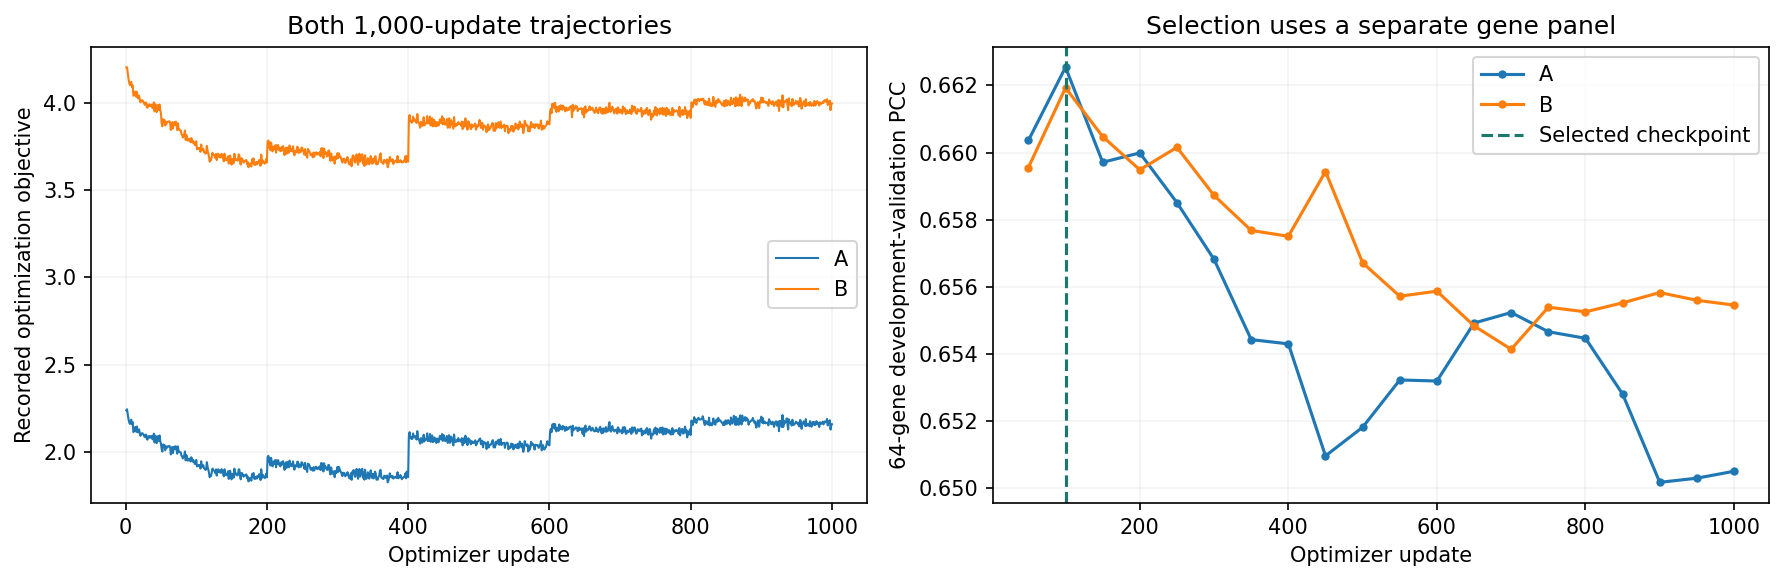

In [17]:
calibration=read_record("FROZEN_CANDIDATES.json")
display(pd.DataFrame(calibration["candidates"])[["name","weight_rna","seed","max_updates"]])
trajectories={};validation_curves=[]
for candidate in ["A","B"]:
    rows=[json.loads(line) for line in (WORKFLOW / f"optimization/{candidate}_updates.jsonl").read_text().splitlines() if line.strip()]
    assert len(rows)==1000 and rows[-1]["step"]==1000
    trajectories[candidate]=rows
    curve=read_record(f"optimization/{candidate}_validation.json")
    validation_curves.extend({"candidate":candidate,**r} for r in curve["rows"])
curve=pd.DataFrame(validation_curves)
selection=curve[curve.eligible].sort_values(["validation_mean","step","candidate"],ascending=[False,True,True]).iloc[0]
recorded=read_record("DEVELOPMENT_SELECTION.json")["selected"]
assert selection.candidate==recorded["candidate"] and int(selection.step)==recorded["step"]
print("Recomputed selection:",selection.candidate,"step",int(selection.step),"validation PCC",selection.validation_mean)

fig,axes=plt.subplots(1,2,figsize=(12,4))
for candidate,rows in trajectories.items():
    axes[0].plot([r["step"] for r in rows],[r["losses"]["loss_3d"] for r in rows],label=candidate,lw=1)
    c=curve[curve.candidate.eq(candidate)]
    axes[1].plot(c.step,c.validation_mean,"o-",label=candidate,ms=3)
axes[0].set(xlabel="Optimizer update",ylabel="Recorded optimization objective",title="Both 1,000-update trajectories")
axes[1].axvline(int(selection.step),color="#1c786b",ls="--",label="Selected checkpoint")
axes[1].set(xlabel="Optimizer update",ylabel="64-gene development-validation PCC",title="Selection uses a separate gene panel")
for ax in axes:ax.legend();ax.grid(alpha=.15)
fig.tight_layout();show_figure(fig)

## 5. Recompute aligned coordinates from the selected weights

**Executed inference.** Load the tensor-only checkpoint and apply its frozen raw-to-coarse transform and nonlinear field to each original coordinate. The selected coordinate NPZ is consulted only to check the result. The coordinate tolerance is 0.001 benchmark-frame pixels; it is not a micrometre calibration.

In [18]:
import torch
from weight_inference import load_weights, align_raw_coordinates
weights = load_weights(DATA_ROOT / "weights/DLPFC/portable_geometry.pth")
assert "expected_xy" not in weights
assert weights["original_checkpoint_sha256"] == manifest["datasets"]["DLPFC"]["weights"][0]["sha256"]
print("Loaded selected geometry parameters; inference on CPU")
print("Checkpoint frame extent:", weights["max_size"])


Loaded selected geometry parameters; inference on CPU
Checkpoint frame extent: 1280


In [19]:
aligned_by_layer = []
raw_by_layer = []
all_ids = []
for layer in range(4):
    record = input_index[("DLPFC", layer)]
    with np.load(INPUT_ROOT / record["path"], allow_pickle=False) as raw:
        original_xy = raw["raw_xy"].copy()
        ids = np.asarray([f"s{layer}_{value}" for value in raw["ids"]])
    predicted_xy, diagnostics = align_raw_coordinates(weights, layer, original_xy)
    assert np.isfinite(predicted_xy).all()
    aligned_by_layer.append(predicted_xy)
    raw_by_layer.append(original_xy)
    all_ids.extend(ids)
aligned_xy = np.concatenate(aligned_by_layer)
reference_coordinates = np.load(DATA_ROOT / manifest["datasets"]["DLPFC"]["coordinates"], allow_pickle=False)
index = {value: i for i, value in enumerate(reference_coordinates["ids"])}
reference_xy = reference_coordinates["nonrigid"][[index[value] for value in all_ids]]
max_coordinate_error = float(np.abs(aligned_xy - reference_xy).max())
assert max_coordinate_error <= 0.001
print("Maximum coordinate difference (benchmark pixels):", max_coordinate_error)
np.savez_compressed(OUTPUT_ROOT / "coordinates_from_weights.npz", ids=np.asarray(all_ids), layers=np.concatenate([np.full(len(x),i) for i,x in enumerate(aligned_by_layer)]), nonrigid=aligned_xy)


Maximum coordinate difference (benchmark pixels): 0.00048828125


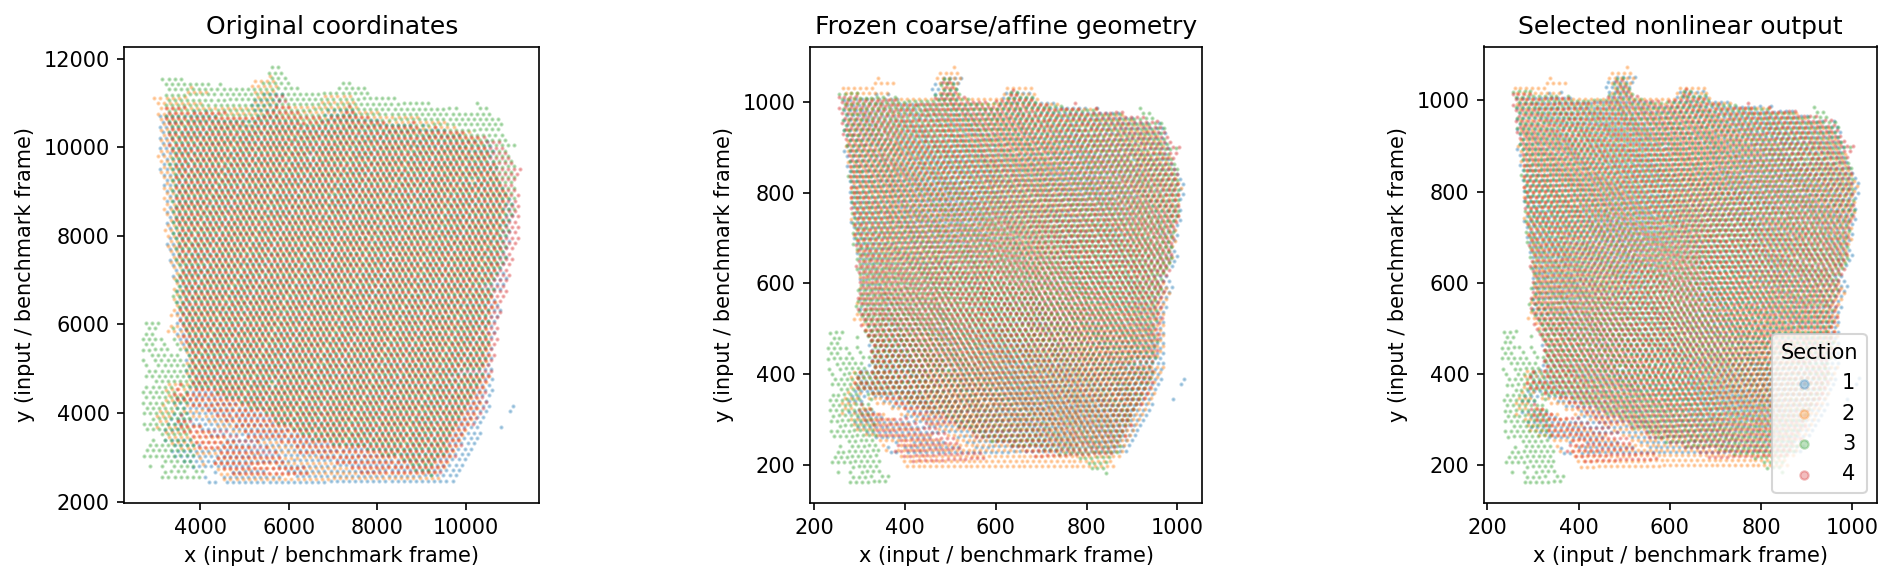

In [20]:
coarse_by_layer=[np.c_[raw,np.ones(len(raw))] @ weights["raw_to_coarse"][layer].numpy() for layer,raw in enumerate(raw_by_layer)]
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,arrays,title in zip(axes,[raw_by_layer,coarse_by_layer,aligned_by_layer],["Original coordinates","Frozen coarse/affine geometry","Selected nonlinear output"]):
    for layer,xy in enumerate(arrays):ax.scatter(*xy.T,s=1,alpha=.3,label=str(layer+1))
    ax.set_title(title);ax.set_aspect("equal");ax.set_xlabel("x (input / benchmark frame)");ax.set_ylabel("y (input / benchmark frame)")
axes[-1].legend(title="Section",markerscale=4)
fig.tight_layout();show_figure(fig)
np.savez_compressed(OUTPUT_ROOT / "coarse_coordinates.npz",ids=np.asarray(all_ids),layers=np.concatenate([np.full(len(x),i) for i,x in enumerate(coarse_by_layer)]),nonrigid=np.concatenate(coarse_by_layer))

## 6. Recompute the final benchmark and compare with the submitted row

**Executed scoring.** All three adjacent pairs use the frozen native scorer and the original final evaluation panel (123 gene arguments, including repeated arguments; 117 unique genes). All six final means must match the submitted DLPFC row. Coarse-stage scores are computed on the same cells and evaluation panel for a descriptive before/after comparison; this does not isolate the causal contribution of the agent.

In [21]:
def load_scoring_slice(dataset, layer, coordinates):
    config = manifest["datasets"][dataset]
    record = input_index[(dataset, layer)]
    with np.load(INPUT_ROOT / record["path"], allow_pickle=False) as raw:
        matrix = sp.csr_matrix((raw["data"], raw["indices"], raw["indptr"]), shape=tuple(raw["shape"]))
        source = ad.AnnData(X=matrix)
        source.obs_names = raw["ids"].astype(str)
        source.var_names = raw["genes"].astype(str)
        source.obs[config["label_column"]] = raw["labels"].astype(str)
        source.obsm["spatial"] = raw["raw_xy"]
    try:
        wanted = [f"s{layer}_{value}" for value in source.obs_names]
        selected = coordinates["layers"] == layer
        ids = coordinates["ids"][selected].tolist()
        assert len(set(ids)) == len(ids) == len(wanted)
        assert set(ids) == set(wanted), (dataset, layer, "Cell identity mismatch")
        lookup = {value: index for index, value in enumerate(ids)}
        order = np.asarray([lookup[value] for value in wanted])
        xy = coordinates["nonrigid"][selected][order]
        keep = coordinates["historical_cohort"][selected][order] if "historical_cohort" in coordinates.files else np.ones(source.n_obs, dtype=bool)
        assert np.isfinite(xy).all() and xy.shape == (source.n_obs, 2)
        unique_genes = list(dict.fromkeys(config["evaluation_genes"]))
        data = source[keep, unique_genes].copy()
        data.obsm["spatial"] = xy[keep]
        data.obs["Region"] = data.obs[config["label_column"]].astype(str)
        if not sp.issparse(data.X):
            data.X = sp.csr_matrix(data.X)
        return data
    finally:
        if source.isbacked:
            source.file.close()

In [22]:
pair_rows=[]
with np.load(OUTPUT_ROOT / "coordinates_from_weights.npz",allow_pickle=False) as coordinates:
    slices=[load_scoring_slice("DLPFC",i,coordinates) for i in range(4)]
    for i in range(3):
        reference_section, moving_section = slices[i], slices[i+1]
        gene_arguments = manifest["datasets"]["DLPFC"]["evaluation_genes"]
        coords = shared_grid(reference_section.obsm["spatial"], moving_section.obsm["spatial"])
        gene_records = []
        for gene_name in gene_arguments:
            X = (reference_section.X[:, reference_section.var_names == gene_name].toarray().squeeze(),
                 moving_section.X[:, moving_section.var_names == gene_name].toarray().squeeze())
            gene_result = {"gene": gene_name}
            for metric, key in zip([PCC, CosSim, SSIM, MI, MSE], NATIVE_KEYS[:5]):
                np.random.seed(0)
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")
                    try:
                        value = float(metric(X, coords))
                        gene_result[key] = value if math.isfinite(value) else None
                        gene_result[key + "_error"] = "" if math.isfinite(value) else "native_nonfinite"
                    except Exception as error:
                        gene_result[key] = None
                        gene_result[key + "_error"] = repr(error)
                gene_result[key + "_warnings"] = " | ".join(str(w.message) for w in caught)
            gene_records.append(gene_result)

        # Equal gene-argument weights. A missing gene score invalidates that pair mean.
        values = {}
        for key in NATIVE_KEYS[:5]:
            numbers = [row[key] for row in gene_records]
            assert len(numbers) == len(gene_arguments)
            values[key] = math.fsum(numbers) / len(numbers) if all(v is not None and math.isfinite(v) for v in numbers) else None

        labels = (reference_section.obs["Region"].to_numpy(), moving_section.obs["Region"].to_numpy())
        values["Accuracy"] = float(Region(labels, coords))
        valid = [pd.notna(g) & (g != "NonOverlap") for g in coords["grid_labels"]]
        valid_grids = [len(set(g[mask])) for g, mask in zip(coords["grid_labels"], valid)]
        support = {"reference_cells": reference_section.n_obs, "moving_cells": moving_section.n_obs,
                   "reference_covered": int(valid[0].sum()), "moving_covered": int(valid[1].sum()),
                   "reference_valid_grids": valid_grids[0], "moving_valid_grids": valid_grids[1],
                   "native_insufficient_grid_fallback": bool(min(valid_grids) < 2)}
        pair_rows.append({"pair_index":i,**values,**support})
means = {}
for (name, key) in zip(METRICS, NATIVE_KEYS):
    numbers = [row[key] for row in pair_rows]
    assert len(numbers) == 3
    means[name] = math.fsum(numbers) / len(numbers) if all(v is not None and math.isfinite(v) for v in numbers) else None
actual = np.array([means[name] for name in METRICS])
expected = reference.loc["DLPFC",METRICS].to_numpy(dtype=float)
np.testing.assert_allclose(actual,expected,atol=1e-10,rtol=0)
display(pd.DataFrame({"From weights":actual,"Current table":expected,"Difference":actual-expected},index=METRICS))
pd.DataFrame(pair_rows).to_csv(OUTPUT_ROOT / "pair_metrics.csv",index=False)
result={"all_six_scores_match":True,"pairs":3,"max_coordinate_difference":max_coordinate_error,"coordinate_tolerance":0.001,"score_tolerance":1e-10,"maximum_score_difference":float(np.abs(actual-expected).max()),"reads_selected_coordinates_as_prediction":False,"coarse_stage":"frozen raw-to-coarse affine transforms"}
save_json(OUTPUT_ROOT / "VALIDATION.json",result)
print(json.dumps(result,indent=2))


,From weights,Current table,Difference
PCC,0.547930,0.547930,0.000000e+00
CosSim,0.783503,0.783503,0.000000e+00
SSIM,0.531970,0.531970,0.000000e+00
MI,0.299724,0.299724,0.000000e+00
MSE,0.127579,0.127579,-2.775558e-17
Region,0.884759,0.884759,0.000000e+00


{
  "all_six_scores_match": true,
  "pairs": 3,
  "max_coordinate_difference": 0.00048828125,
  "coordinate_tolerance": 0.001,
  "score_tolerance": 1e-10,
  "maximum_score_difference": 2.7755575615628914e-17,
  "reads_selected_coordinates_as_prediction": false,
  "coarse_stage": "frozen raw-to-coarse affine transforms"
}


In [23]:
coarse_rows=[]
with np.load(OUTPUT_ROOT / "coarse_coordinates.npz",allow_pickle=False) as coordinates:
    coarse_slices=[load_scoring_slice("DLPFC",i,coordinates) for i in range(4)]
    for i in range(3):
        reference_section, moving_section = coarse_slices[i], coarse_slices[i+1]
        gene_arguments = manifest["datasets"]["DLPFC"]["evaluation_genes"]
        coords = shared_grid(reference_section.obsm["spatial"], moving_section.obsm["spatial"])
        gene_records = []
        for gene_name in gene_arguments:
            X = (reference_section.X[:, reference_section.var_names == gene_name].toarray().squeeze(),
                 moving_section.X[:, moving_section.var_names == gene_name].toarray().squeeze())
            gene_result = {"gene": gene_name}
            for metric, key in zip([PCC, CosSim, SSIM, MI, MSE], NATIVE_KEYS[:5]):
                np.random.seed(0)
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")
                    try:
                        value = float(metric(X, coords))
                        gene_result[key] = value if math.isfinite(value) else None
                        gene_result[key + "_error"] = "" if math.isfinite(value) else "native_nonfinite"
                    except Exception as error:
                        gene_result[key] = None
                        gene_result[key + "_error"] = repr(error)
                gene_result[key + "_warnings"] = " | ".join(str(w.message) for w in caught)
            gene_records.append(gene_result)

        # Equal gene-argument weights. A missing gene score invalidates that pair mean.
        values = {}
        for key in NATIVE_KEYS[:5]:
            numbers = [row[key] for row in gene_records]
            assert len(numbers) == len(gene_arguments)
            values[key] = math.fsum(numbers) / len(numbers) if all(v is not None and math.isfinite(v) for v in numbers) else None

        labels = (reference_section.obs["Region"].to_numpy(), moving_section.obs["Region"].to_numpy())
        values["Accuracy"] = float(Region(labels, coords))
        valid = [pd.notna(g) & (g != "NonOverlap") for g in coords["grid_labels"]]
        valid_grids = [len(set(g[mask])) for g, mask in zip(coords["grid_labels"], valid)]
        support = {"reference_cells": reference_section.n_obs, "moving_cells": moving_section.n_obs,
                   "reference_covered": int(valid[0].sum()), "moving_covered": int(valid[1].sum()),
                   "reference_valid_grids": valid_grids[0], "moving_valid_grids": valid_grids[1],
                   "native_insufficient_grid_fallback": bool(min(valid_grids) < 2)}
        coarse_rows.append(values)
coarse_means = {}
for (name, key) in zip(METRICS, NATIVE_KEYS):
    numbers = [r[key] for r in coarse_rows]
    assert len(numbers) == 3
    coarse_means[name] = math.fsum(numbers) / len(numbers) if all(v is not None and math.isfinite(v) for v in numbers) else None
comparison=pd.DataFrame({"Coarse / affine":coarse_means,"Selected nonlinear":means,"Submitted table":reference.loc["DLPFC",METRICS].to_dict()})
comparison["Selected minus coarse"]=comparison["Selected nonlinear"]-comparison["Coarse / affine"]
display(comparison.round(6))
comparison.to_csv(OUTPUT_ROOT / "coarse_vs_selected.csv")

,Coarse / affine,Selected nonlinear,Submitted table,Selected minus coarse
PCC,0.541410,0.547930,0.547930,0.006519
CosSim,0.780252,0.783503,0.783503,0.003251
SSIM,0.524414,0.531970,0.531970,0.007556
MI,0.308726,0.299724,0.299724,-0.009002
MSE,0.126226,0.127579,0.127579,0.001352
Region,0.874471,0.884759,0.884759,0.010288


## 7. What this example establishes

The notebook exposes the recorded detector evidence, stage reviews, local-refinement decision, optimization trajectory, selection rule, weights, coordinates and final scoring. It reproduces the submitted molecular metrics for this selected development condition. It does not establish that the agent alone caused the gain, nor that all local anatomy was validated. The archived final status below is part of the result.

In [24]:
final_status=read_record("FINAL_STATUS.json")
status={key:final_status[key] for key in ["scoring_completed","geometry_admitted","registration_success","formal_pipeline_resume"]}
display(pd.DataFrame([status]))
assert status["scoring_completed"] and not status["geometry_admitted"]
report=json.loads((OUTPUT_ROOT / "VALIDATION.json").read_text())
report.update({"workflow_files_verified":len(evidence_manifest["files"]),"archived_agent_reviews":len(reviews),"recorded_optimizer_updates_per_candidate":1000,"selected_candidate":str(selection.candidate),"selected_step":int(selection.step),"fresh_LLM_calls":0,"fresh_optimizer_updates":0,"coarse_metrics_recomputed":True,"archived_final_status":status})
save_json(OUTPUT_ROOT / "VALIDATION.json",report)
print("PASS: recorded workflow verified; coordinates and six final scores recomputed.")

,scoring_completed,geometry_admitted,registration_success,formal_pipeline_resume
0,True,False,False,False


PASS: recorded workflow verified; coordinates and six final scores recomputed.
